# Build Forcing Validation - Temperature
- Tony Grove

In [1]:
%matplotlib ipympl
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from buildforcing.datasets import PNNLSnotel
from gdriver.gdriver import get_credentials, getCSVtoPandas
import os

In [2]:
# Run parameters
site = 'Tony Grove RS'
latitude = 41.89
longitude = -111.57
start_date = '20150101'
end_date = '20150301'
buildforcing_version = 'v0.1.0'
#environment = '/home/chriscox/Data/'
environment = 'C:/Users/clmbn/NMT_PhD/data/' # Windows

### Load datasets

In [3]:
# Load the forcing dataset
sitename = site.replace(' ', '').lower()
tg_forcing = xr.open_dataset(os.path.join(environment,'forcing',f'{sitename}_{start_date}_{end_date}_{buildforcing_version}.nc'))

In [4]:
tg_forcing

<xarray.Dataset> Size: 104kB
Dimensions:           (latitude: 1, longitude: 1, time: 1440)
Coordinates:
  * latitude          (latitude) float64 8B 41.89
  * longitude         (longitude) float64 8B -111.6
  * time              (time) datetime64[ns] 12kB 2015-01-01 ... 2015-03-01T23...
Data variables:
    LWdown            (time, latitude, longitude) float64 12kB ...
    SWdown            (time, latitude, longitude) float64 12kB ...
    Psurf             (time, latitude, longitude) float64 12kB ...
    Qair              (time, latitude, longitude) float64 12kB ...
    Tair              (time, latitude, longitude) float64 12kB ...
    Rainf             (time, latitude, longitude) float64 12kB ...
    Snowf             (time, latitude, longitude) float64 12kB ...
    Wind              (time, latitude, longitude) float64 12kB ...
    reference_height  (latitude, longitude) int64 8B ...
    canopy_height     (latitude, longitude) float64 8B ...

In [5]:
# Extract Tair from dataset to a pandas dataframe ignoring the lat/lon dimensions
# and keeping the time dimension
forcing_Tair = tg_forcing['Tair'].isel(latitude=0, longitude=0)
forcing_Tair = forcing_Tair.to_dataframe()

In [6]:
# Convert temperature from Kelvin to Celsius
forcing_Tair['Tair_C'] = forcing_Tair['Tair'] - 273.15

In [7]:
forcing_Tair.index = forcing_Tair.index.tz_localize('UTC').tz_convert('America/Denver')

In [8]:
snotel = PNNLSnotel(site_name=site, storage_path=os.path.join(environment, 'snotel'))

In [9]:
snotel.data.head()

,T_max_C,T_min_C,T_avg_C,precip_mm,swe_mm
Date,,,,,
2009-06-08 00:00:00-06:00,NaN,NaN,NaN,NaN,0.0
2009-06-09 00:00:00-06:00,NaN,NaN,NaN,NaN,0.0
2009-06-10 00:00:00-06:00,12.261111,5.394444,8.255556,NaN,0.0
2009-06-11 00:00:00-06:00,13.405556,5.394444,8.255556,NaN,0.0
2009-06-12 00:00:00-06:00,17.411111,4.822222,10.544444,NaN,0.0


In [ ]:
nldas_forcing = xr.open_dataset(os.path.join(environment,'nldas',f'NLDAS_{latitude}_{longitude}_{start_date}_{end_date}.nc'))

In [17]:
nldas_Tair = nldas_forcing['Tair'].to_dataframe()
nldas_Tair['Tair_C'] = nldas_Tair['Tair'] - 273.15
nldas_Tair.index = nldas_Tair.index.tz_localize('UTC').tz_convert('America/Denver')

#### Load GAMUT

In [11]:
# Load gdriver credentials
credentials = get_credentials()

# Get the ST110 data
gamut_st110 = getCSVtoPandas('TonyGrove/LR_TG_C_AirTemp_ST110_Avg_SourceID_1_QC_1.csv',credentials,skiprows=56)

# Change index to DateTimeUTC
gamut_st110['DateTime'] = pd.to_datetime(gamut_st110['LocalDateTime'])
gamut_st110 = gamut_st110.set_index('DateTime')

# Convert -9999 to NaN
gamut_st110 = gamut_st110.replace(-9999, np.nan)

Download 100.


In [14]:
# Extract a subset of the data for the time period of interest
start_date = '2015-01-01 00:00:00'
end_date = '2015-03-01 00:00:00'
gamut_st110_month = gamut_st110.loc[start_date:end_date]

# Localize datetime to america/denver timezone
gamut_st110_month.index = gamut_st110_month.index.tz_localize('America/Denver')

## Comparisons

<Axes: xlabel='Date'>

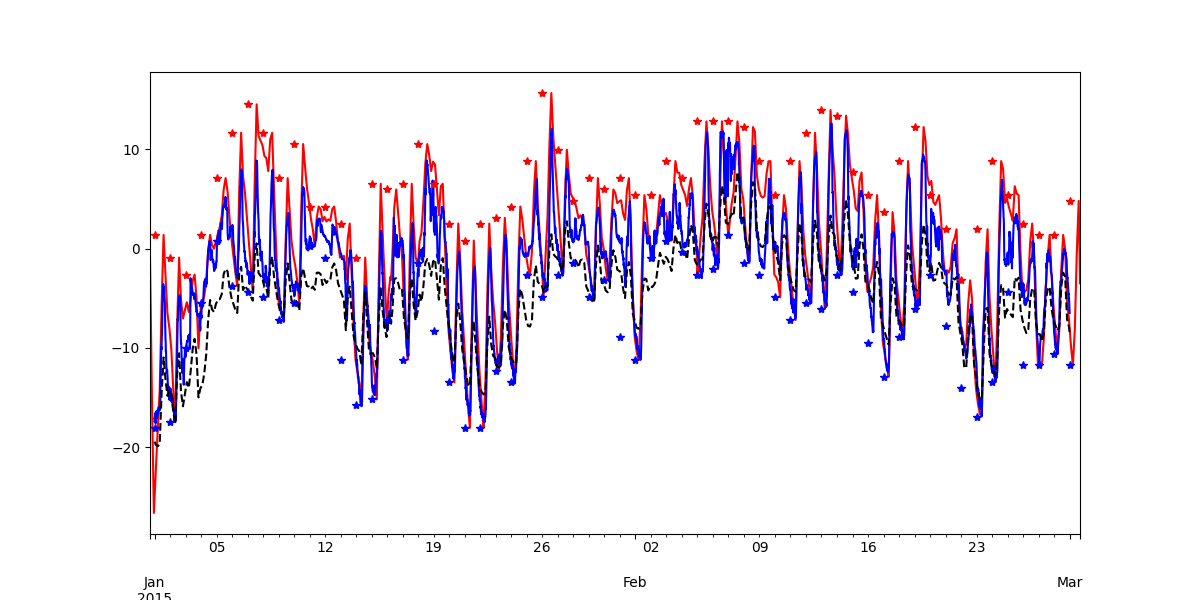

In [18]:
# Plot Tair and compare to ST110 data
fig, ax = plt.subplots(figsize=(12, 6))
forcing_Tair['Tair_C'].plot(ax=ax, label='Forcing Tair (C)', color='red')
gamut_st110_month['AirTemp_ST110_Avg'].plot(ax=ax, label='GAMUT Tair (C)', color='blue')
nldas_Tair['Tair_C'].loc[start_date:end_date].plot(ax=ax, label='NLDAS Tair (C)', style='k--')
snotel.data.loc[start_date:end_date,'T_max_C'].plot(ax=ax, label='SNOTEL Tair (C)', style='r*')
snotel.data.loc[start_date:end_date,'T_min_C'].plot(ax=ax, label='SNOTEL Tair (C)', style='b*')

#

In [ ]:
# Plot SWdown and compare to SP230 data
fig, ax = plt.subplots(figsize=(12, 6))
forcing_SWdown['SWdown'].plot(ax=ax, label='Forcing SWdown (W/m2)', color='blue')
gamut_sp230_month['SWIn_SP230_Avg'].plot(ax=ax, label='GAMUT SWdown (W/m2)', color='red')